# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maraña, Kyle
- _Student No._: 2024-14996
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Figure 1. Initial spin configuration** (random, $20\times20$, $T=1$ chosen for the run that follows).

![A](fig1.png)

- **What is the expected initial magnetization?** The expected initial magnetization is zero. Each spin is randomly $+1$ or $-1$ with equal probability, so the up and down spins cancel on average. My lattice came out at exactly $m = 0.000$.
- **What is the energy of a completely aligned lattice when $J>0$?** The energy is $-2JN^2$, which is $-800$ for $N = 20$ and $J = 1$. In a fully aligned lattice every one of the $2N^2$ neighbouring pairs contributes $-J$, so this is the lowest energy the system can have.

**Figure 2. Spin configuration after 10,000 sweeps, $T$ below and above $T_C$**

![A](fig2.png)

**Figure 3. Magnetization and energy (B = 0), $T$ below and above $T_C$**

![A](fig3.png)

- **Does the system develop spontaneous magnetization?** Yes, but only below $T_C$. At $T = 1$ the lattice starts with $m \approx 0$ and orders by itself, ending at $|m| \approx 1$ with an energy of about $-2$ per spin, even though there is no external field. At $T = 3$, which is above $T_C$, it does not: $m$ just fluctuates around zero.
- **Why can separate simulations produce positive or negative magnetization?** The Hamiltonian does not change if every spin is flipped, so a state with $+m$ and one with $-m$ have exactly the same energy and probability. The system has to choose one of the two, and which one it picks differs from run to run. In my four runs at $T = 1$, three ended at $m = +1$ and one ended at $m = -1$.
- **What determines the preferred spin orientation?** Nothing in the physics prefers one direction, so it is decided by chance. The random initial lattice and the first few accepted flips determine which orientation forms a domain that grows and takes over the lattice.

**Figure 4. Magnetization and energy with external field ($B=0.5$), $T$ below and above $T_C$**

![A](fig4.png)

- **How does the external magnetic field affect spin alignment?** The field pushes spins to line up with it. The term $-B\sum S$ lowers the energy of spins parallel to the field, so flipping a down spin up lowers the energy by $2B$ and these flips are favoured. At $T = 1$ the lattice becomes fully aligned ($m = +1$) in about 10 sweeps, compared with about 70 without a field. At $T = 3$ the alignment is only partial ($m \approx 0.75$), because thermal motion still randomises some spins.
- **Why does the system favor one magnetization direction over the other?** The field breaks the up/down symmetry. The spin-up state has lower energy and so a larger Boltzmann weight than the spin-down state, and the sign of $m$ follows the sign of $B$ no matter what the starting lattice is. The opposite orientation is only metastable, and at $T = 1$ the system practically never goes there.
- **Above $T_C$ (Section 5):** Sections 2 to 4 were repeated at $T = 3$, where flips that raise the energy are accepted much more often, so random flips keep breaking up any alignment, leaving the lattice mixed after 10,000 sweeps (Figure 2) with $m$ fluctuating around zero when there is no field (Figure 3) and the energy near $-296$ instead of $-800$, while with the field the spins only partly align, with $m \approx 0.74$ and $E \approx -656$ (Figure 4), which is expected because $T = 3$ is above $T_C \approx 2.269$.

### Report discussion

**Figure 1.** Figure 1 shows the random starting lattice, with up and down spins scattered and no pattern. Its magnetization is 0.000 and its energy is $-32$, far above the fully aligned value of $-800$. Neighbouring spins are as likely to be opposite as parallel, so this is a high-energy, disordered state that the Metropolis dynamics must relax.

**Figure 2.** Figure 2 shows the lattices after 10,000 sweeps. At $T = 1$ the lattice is fully ordered, with $E = -800$ for $B = 0$ and $E = -1000$ for $B = 0.5$, both with $m = +1$. At $T = 3$ it stays disordered, with $m = -0.140$ and $E = -296$ for $B = 0$, and mostly up with $B = 0.5$ ($m = +0.740$, $E = -656$).

**Figure 3.** Figure 3 compares energy and magnetization with no field. At $T = 1$ the energy drops to about $-2$ per spin and $|m|$ rises to about 1 within roughly 70 sweeps, after which both barely fluctuate. At $T = 3$ the energy stays near $-0.8$ and $m$ fluctuates around zero, so no order forms.

**Figure 4.** Figure 4 repeats this with $B = 0.5$. At $T = 1$ the lattice is fully magnetized within about 10 sweeps, and the energy settles near $-2.5$, the ground-state value. At $T = 3$ the field only partly aligns the spins, with $m$ fluctuating around 0.75 and the energy around $-1.75$ per spin.

### Other comments
- :/


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

## Parameters

In [2]:
N = 20
J = 1.0
K_B = 1.0
B_field = 0.5
T_low = 1.0   # below  Tc ~ 2.269
T_high = 3.0  # above Tc ~ 2.269
n_sweeps = 10000
burn = 1000   # sweeps discarded as equilibration when averaging
rng = np.random.default_rng(202414996)

## 1. Setting Up the Ising Model

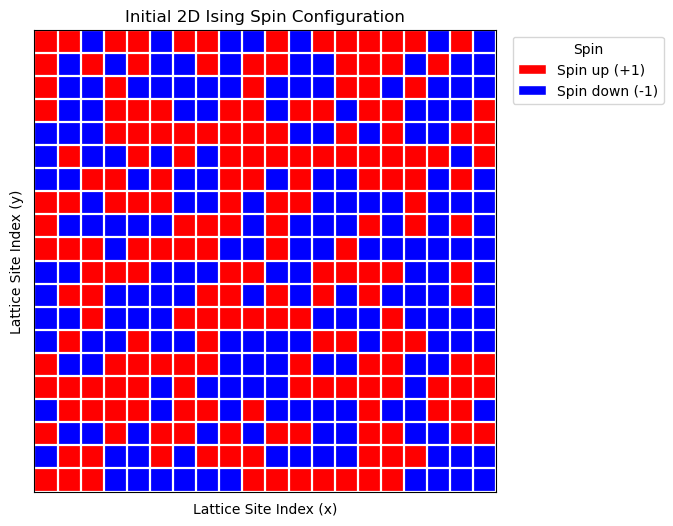

Initial energy: -32.0  (-0.0800 per spin)
Initial magnetization per spin: +0.0000  (expected ~ 0)
Fully aligned lattice energy: -800.0  (= -2 J N^2 = -800.0)
Max |dH(formula) - dH(full recompute)| over 1000 flips: 0.0


In [3]:
lattice = rng.choice([1, -1], size=(N, N))

def show_lattice(ax, S, title):
    ax.imshow(S, cmap='bwr', origin='upper', vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xlabel('Lattice Site Index (x)')
    ax.set_ylabel('Lattice Site Index (y)')
    ax.set_xticks(np.arange(-0.5, N, 1)) 
    ax.set_yticks(np.arange(-0.5, N, 1))
    ax.set_xticklabels([]) 
    ax.set_yticklabels([])
    ax.tick_params(length=0)
    ax.grid(color='white', linewidth=1.6)
    cmap = plt.cm.bwr
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='white', label='Spin up (+1)'),
               plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='white', label='Spin down (-1)')]
    ax.legend(handles=handles, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

fig, ax = plt.subplots(figsize=(6, 6))
show_lattice(ax, lattice, 'Initial 2D Ising Spin Configuration')
plt.savefig('fig1.png', bbox_inches='tight')
plt.show()

def hamiltonian(lattice):
    down = np.roll(lattice, -1, axis=0)
    right = np.roll(lattice, -1, axis=1)
    return -J * np.sum(lattice * (down + right))

def mod_hamiltonian(lattice, B):
    return hamiltonian(lattice) - B * np.sum(lattice)

print(f"Initial energy: {hamiltonian(lattice):.1f}  ({hamiltonian(lattice)/N**2:.4f} per spin)")
print(f"Initial magnetization per spin: {lattice.mean():+.4f}  (expected ~ 0)")
print(f"Fully aligned lattice energy: {hamiltonian(np.ones((N, N))):.1f}  (= -2 J N^2 = {-2*J*N**2:.1f})")

# check of the flip cost, formula vs full recomputation, for 1000 random single flips
B_test, worst = 0.5, 0.0
for _ in range(1000):
    i, j = rng.integers(0, N, size=2)
    nn = (lattice[(i+1) % N, j] + lattice[(i-1) % N, j] + lattice[i, (j+1) % N] + lattice[i, (j-1) % N])
    dH_formula = 2 * lattice[i, j] * (J * nn + B_test)
    flipped = lattice.copy()
    flipped[i, j] *= -1
    dH_full = mod_hamiltonian(flipped, B_test) - mod_hamiltonian(lattice, B_test)
    worst = max(worst, abs(dH_formula - dH_full))
print(f"Max |dH(formula) - dH(full recompute)| over 1000 flips: {worst}")
assert worst < 1e-12

# 2. Implementing the Metropolis Algorithm

Test run T=1.0, B=0: final E=-800.0, final m=+1.000


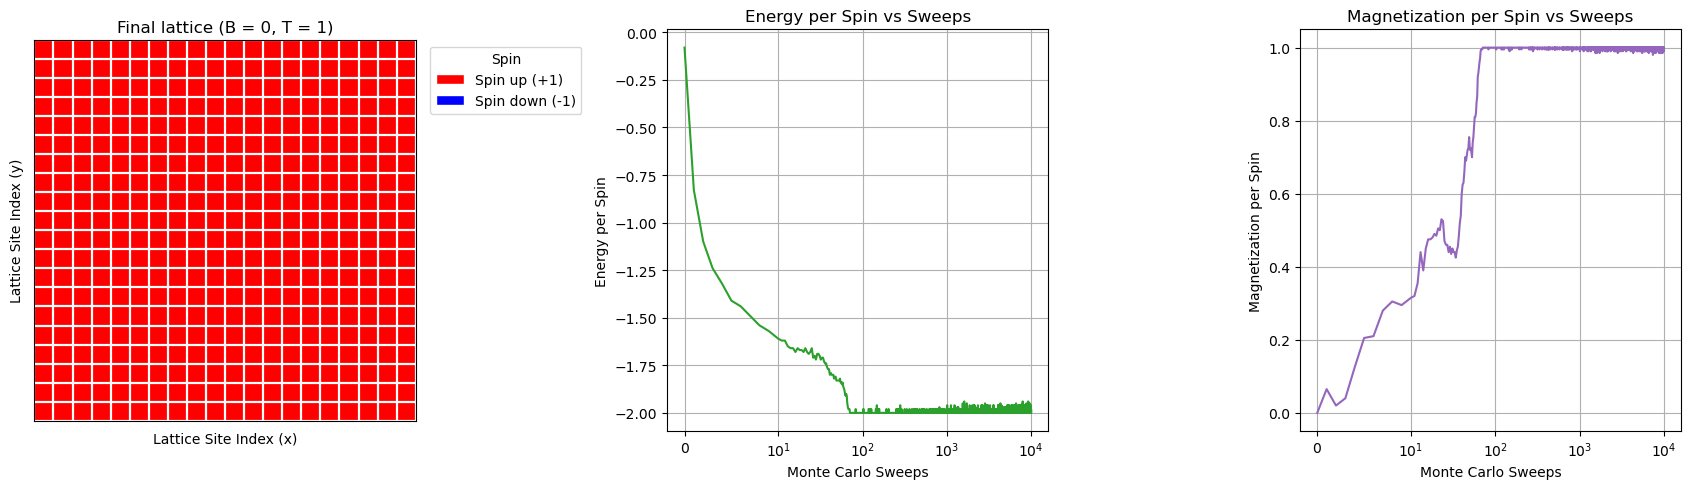

In [4]:
def metropolis(lattice, B, T, n_sweeps):
    S = [int(x) for x in lattice.ravel()]
    NBR = [] # periodic neighbour table
    for s in range(N * N):
        i, j = divmod(s, N)
        NBR.append((((i+1) % N)*N + j, ((i-1) % N)*N + j, i*N + (j+1) % N, i*N + (j-1) % N))
    dH_tab, p_tab = [0.0]*10, [1.0]*10 # flip cost and acceptance probability
    for s in (-1, 1):
        for nn in (-4, -2, 0, 2, 4):
            k = (s + 1)//2*5 + (nn + 4)//2
            dH = 2*J*s*nn + 2*B*s
            dH_tab[k] = dH
            p_tab[k] = 1.0 if dH <= 0 else math.exp(-dH/(K_B*T))
    M = sum(S)
    E = float(mod_hamiltonian(lattice, B))
    energies = np.empty(n_sweeps + 1) 
    mags = np.empty(n_sweeps + 1)
    energies[0], mags[0] = E, M
    for sweep in range(n_sweeps):
        picks = rng.integers(0, N*N, size=N*N).tolist()
        rands = rng.random(N*N).tolist()
        for site, r in zip(picks, rands):
            a, b, c, d = NBR[site]
            s = S[site]
            k = (s + 1)//2*5 + (S[a] + S[b] + S[c] + S[d] + 4)//2
            if r < p_tab[k]:
                M -= 2*s; E += dH_tab[k]; S[site] = -s
        energies[sweep + 1] = E
        mags[sweep + 1] = M
    S = np.array(S).reshape(N, N)
    assert abs(E - mod_hamiltonian(S, B)) < 1e-9
    return S, energies, mags

# test run T = 1, B = 0
S_test, E_test, M_test = metropolis(lattice, 0, T_low, n_sweeps=n_sweeps)
print(f"Test run T={T_low}, B=0: final E={E_test[-1]:.1f}, final m={M_test[-1]/N**2:+.3f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
show_lattice(ax[0], S_test, 'Final lattice (B = 0, T = 1)')
ax[1].plot(E_test/N**2, color='tab:green') 
ax[1].set_xscale('symlog', linthresh=10)
ax[1].set_title('Energy per Spin vs Sweeps')
ax[1].set_xlabel('Monte Carlo Sweeps')
ax[1].set_ylabel('Energy per Spin')
ax[1].grid()

ax[2].plot(M_test/N**2, color='tab:purple')
ax[2].set_xscale('symlog', linthresh=10)
ax[2].set_title('Magnetization per Spin vs Sweeps')
ax[2].set_xlabel('Monte Carlo Sweeps')
ax[2].set_ylabel('Magnetization per Spin')
ax[2].grid()

plt.tight_layout()
plt.savefig('test_run.png', bbox_inches='tight')
plt.show()

## 3. Investigating Spontaneous Magnetization

In [5]:
n_runs = 4  # number of different random initial lattices

def run_many(T, B, n_runs):
    curves = []
    for _ in range(n_runs):
        init = rng.choice([1, -1], size=(N, N))
        _, _, M_k = metropolis(init, B, T, n_sweeps=n_sweeps)
        curves.append(M_k / N**2)
    return curves

final_lattice, energies, magnetization = S_test, E_test, M_test   # B = 0, T = 1 (totals, not per spin)

curves_low = run_many(T_low, 0, n_runs)
finals = np.array([c[-1] for c in curves_low])
print(f"{n_runs} random initial lattices at T={T_low}, B=0: {(finals > 0).sum()} ended m>0, {(finals < 0).sum()} ended m<0")


4 random initial lattices at T=1.0, B=0: 3 ended m>0, 1 ended m<0


## 4. Introducing an External Magnetic Field & 5. Critical Temperature

In [6]:
final_latwB, enerwB, magnetwB = metropolis(lattice, B_field, T_low, n_sweeps=n_sweeps)
print(f"B={B_field}, T={T_low}: final E={enerwB[-1]:.1f}, final m={magnetwB[-1]/N**2:+.3f}")

B=0.5, T=1.0: final E=-1000.0, final m=+1.000


In [7]:
final_lattice3, energies3, magnetization3 = metropolis(lattice, 0, T_high, n_sweeps=n_sweeps)
final_latwB3, enerwB3, magnetwB3 = metropolis(lattice, B_field, T_high, n_sweeps=n_sweeps)
print(f"B=0, T={T_high}: final E={energies3[-1]:.1f}, final m={magnetization3[-1]/N**2:+.3f}")
print(f"B={B_field}, T={T_high}: final E={enerwB3[-1]:.1f}, final m={magnetwB3[-1]/N**2:+.3f}")

B=0, T=3.0: final E=-296.0, final m=-0.140
B=0.5, T=3.0: final E=-656.0, final m=+0.740


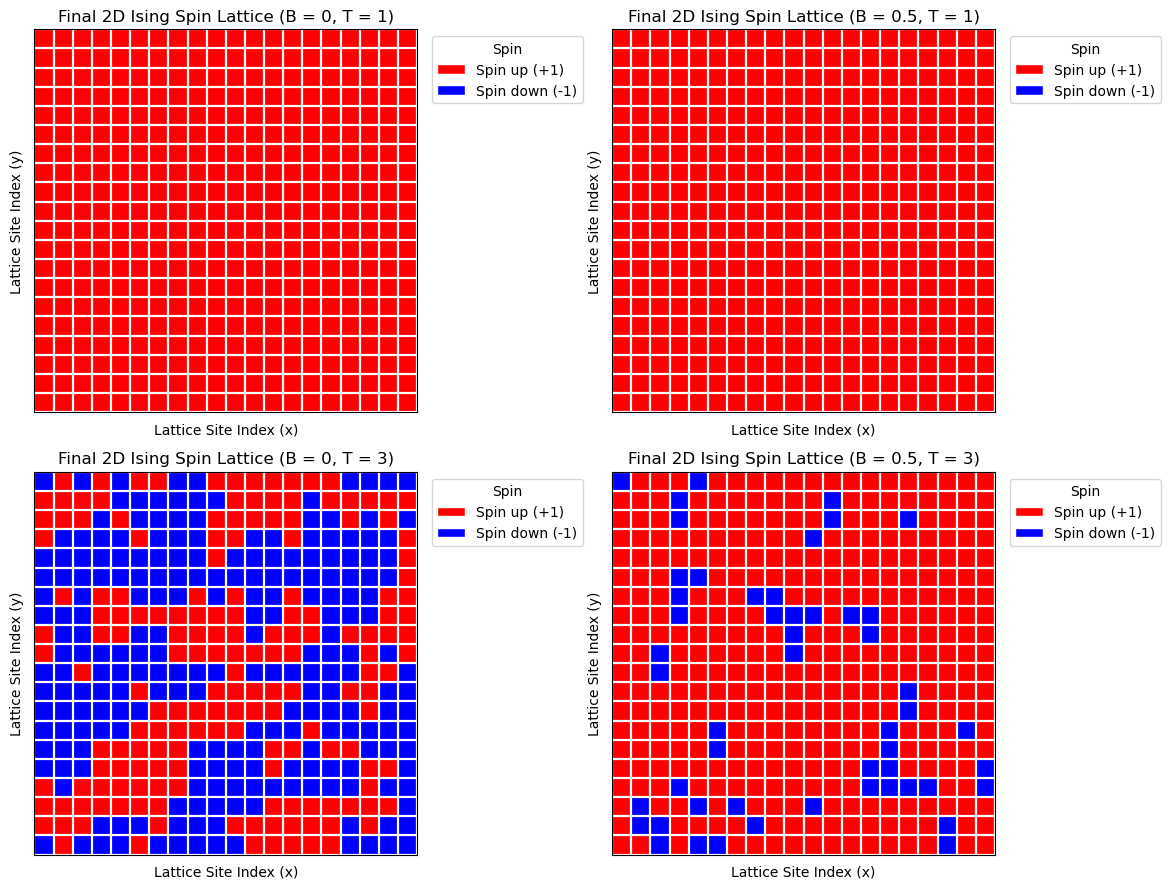

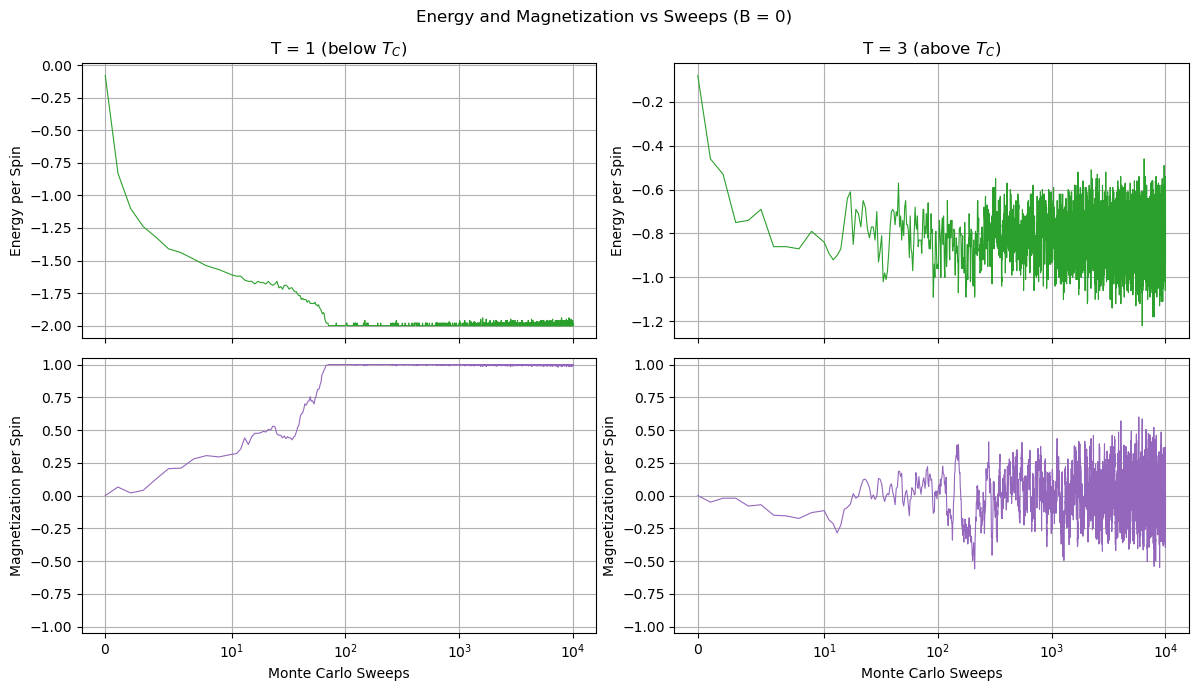

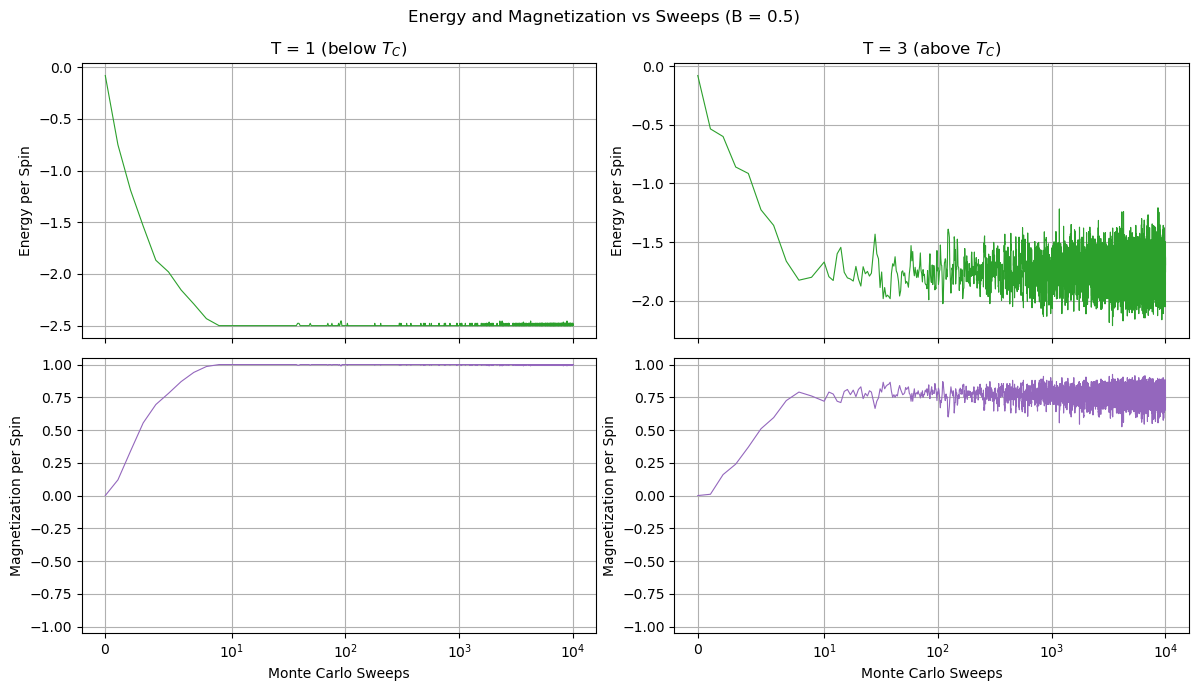

In [8]:
# final spin configurations after 10,000 sweeps
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
show_lattice(axs[0, 0], final_lattice,  'Final 2D Ising Spin Lattice (B = 0, T = 1)')
show_lattice(axs[0, 1], final_latwB,    f'Final 2D Ising Spin Lattice (B = {B_field}, T = 1)')
show_lattice(axs[1, 0], final_lattice3, 'Final 2D Ising Spin Lattice (B = 0, T = 3)')
show_lattice(axs[1, 1], final_latwB3,   f'Final 2D Ising Spin Lattice (B = {B_field}, T = 3)')
plt.tight_layout()
plt.savefig('fig2.png', dpi=300)
plt.show()

# energy and magnetization, T below vs above Tc
def plot_EM(E_lo, M_lo, E_hi, M_hi, title, fname):
    fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    data = [(E_lo, M_lo, T_low, 'below'), (E_hi, M_hi, T_high, 'above')]
    for col, (E, M, T, side) in enumerate(data):
        axs[0, col].plot(E / N**2, color='tab:green', lw=0.8)
        axs[1, col].plot(M / N**2, color='tab:purple', lw=0.8)
        axs[0, col].set_title(f'T = {T:g} ({side} $T_C$)')
        axs[0, col].set_ylabel('Energy per Spin')
        axs[1, col].set_ylabel('Magnetization per Spin')
        axs[1, col].set_xlabel('Monte Carlo Sweeps')
        axs[1, col].set_ylim(-1.05, 1.05)
        for ax in axs[:, col]:
            ax.set_xscale('symlog', linthresh=10)     # shows the early transient and the long plateau
            ax.grid()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(fname, bbox_inches='tight')
    plt.show()

plot_EM(energies, magnetization, energies3, magnetization3,
        'Energy and Magnetization vs Sweeps (B = 0)', 'fig3.png')
plot_EM(enerwB, magnetwB, enerwB3, magnetwB3,
        f'Energy and Magnetization vs Sweeps (B = {B_field})', 'fig4.png')

### Random initial lattices above $T_C$

T=3.0, B=0, time-averaged m after 1000 sweeps for each run: ['-0.004', '+0.015', '-0.001', '-0.011']


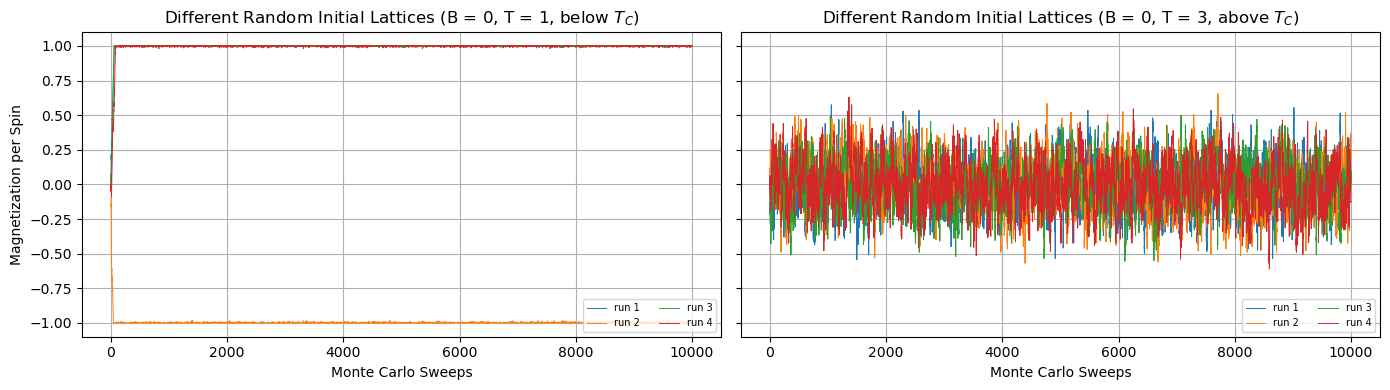

In [9]:
# different random initial lattices, T above Tc (B = 0)
curves_high = run_many(T_high, 0, n_runs)
print(f"T={T_high}, B=0, time-averaged m after 1000 sweeps for each run:",
      [f"{c[burn:].mean():+.3f}" for c in curves_high])

fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, curves, T, side in [(axs[0], curves_low, T_low, 'below'), (axs[1], curves_high, T_high, 'above')]:
    for k, c in enumerate(curves):
        ax.plot(c, lw=0.7, label=f'run {k+1}')
    ax.set_title(f'Different Random Initial Lattices (B = 0, T = {T:g}, {side} $T_C$)')
    ax.set_xlabel('Monte Carlo Sweeps')
    ax.grid(); ax.legend(fontsize=7, ncol=2, loc='lower right')
axs[0].set_ylabel('Magnetization per Spin')
plt.tight_layout()
plt.show()

#### Problem code summary
This code simulates the two-dimensional Ising model on a $20 \times 20$ periodic lattice with the Metropolis Monte Carlo algorithm, to see how temperature and an external field affect the energy and magnetization. The total energy is computed by `hamiltonian` with `np.roll`, which wraps the lattice around so every bond is counted once, and `mod_hamiltonian` adds the field term $-B\sum S$. The single-spin-flip energy change $\Delta H = 2S[J(\text{neighbour sum}) + B]$ is checked against a full energy recomputation over 1000 random flips, and the aligned-lattice energy is checked against $-2JN^2$. The `metropolis` function builds a periodic neighbour table once, plus a lookup table of $\Delta H$ and the acceptance probability $\min(1, e^{-\Delta H/k_BT})$ for the 10 possible combinations of spin and neighbour sum, so no exponential or full-lattice sum is needed for each attempted flip. Each sweep draws $N^2$ random sites and acceptance numbers at once, then attempts one flip at a time. The running energy and magnetization are updated incrementally after every accepted flip, and a final `assert` confirms the incremental energy matches a full recomputation. The same function takes $T$ and $B$ as arguments, so it is reused for $T = 1$ and $T = 3$, with and without the field, for 10,000 sweeps each. A single seeded random generator keeps every run reproducible when the notebook is run from top to bottom, and `run_many` starts four runs from different random lattices at each temperature for the comparison of spontaneous magnetization.